# UNIVERSIDAD NACIONAL DE INGENIERÍA — MAESTRÍA EN INTELIGENCIA ARTIFICIAL
## Informe experimental: EDA + Feature Engineering + Baseline y dos variantes de datos
**Proyecto de tesis:** Diseño, simulación y evaluación comparativa de DDPG autónomo y arquitecturas híbridas DDPG–LQR y DDPG–ISMC para el balanceo y la estabilización robusta del péndulo invertido tipo Cart-Pole.

**Objetivo de la Tesis:** Diseñar, simular y comparar la capacidad de una política DDPG autónoma y dos esquemas híbridos para levantar el péndulo desde configuraciones alejadas del equilibrio, capturar la vertical, conservar estabilidad y responder a perturbaciones bajo restricciones comunes de fuerza y riel.

**Fuente:** datos originales de simulación y archivo `metricas_5_folds.csv` que contiene resultados precomputados del experimento *Leave-One-Seed-Out* (LOSO). **Este cuaderno no reentrena DDPG ni vuelve a ejecutar la validación cruzada:** documenta y audita esos resultados.

**Orden:** configuración → carga → EDA → Feature Engineering → diseño Baseline/variantes → resultados LOSO → conclusiones → exportación.



## 1. Librerías utilizadas
- **pandas y NumPy:** manipulación y cálculo numérico.
- **Matplotlib y Seaborn:** figuras, distribuciones, correlaciones.
- **scikit-learn:** clasificador auxiliar, matriz de confusión y métricas.
- **Google Colab / Drive:** acceso a los archivos de simulación.

Colab normalmente incluye estas librerías; la primera celda solo instala lo que falte.

In [ ]:
import importlib.util, subprocess, sys
requeridas = {'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','seaborn':'seaborn','sklearn':'scikit-learn'}
faltantes = [paquete for modulo, paquete in requeridas.items() if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *faltantes])
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display, Markdown
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, balanced_accuracy_score, f1_score
from sklearn.ensemble import HistGradientBoostingClassifier
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 14)
print('Librerías cargadas. pandas:',pd.__version__)

Librerías cargadas. pandas: 2.2.3


In [ ]:
from pathlib import Path
ruta_drive = Path('/content/drive/MyDrive/CartPole_Tesis')
print('Carpeta Drive visible desde entorno Python:', ruta_drive.is_dir())
print('No se requiere montar Drive: se puede trabajar con archivos subidos a /content.')

Carpeta Drive visible desde entorno Python: False
No se requiere montar Drive: se puede trabajar con archivos subidos a /content.


In [ ]:
from pathlib import Path
from google.colab import files
archivo = Path('/content/caracteristicas_paso_a_paso.csv')
if archivo.is_file():
    print('CSV principal ya disponible:', archivo)
else:
    print('Seleccione caracteristicas_paso_a_paso.csv para subirlo a Colab.')
    archivos_subidos = files.upload()
    archivo = Path('/content/caracteristicas_paso_a_paso.csv')
    if not archivo.is_file():
        raise FileNotFoundError('No se encontró el CSV principal en /content.')

Seleccione caracteristicas_paso_a_paso.csv para subirlo a Colab.


Saving caracteristicas_paso_a_paso.csv to caracteristicas_paso_a_paso.csv


## 2. Carga y verificación de los datos experimentales
**Fuente principal:** `caracteristicas_paso_a_paso.csv` — 600.000 transiciones y 45 columnas (variables originales y derivadas).

Los archivos están almacenados por el estudiante en **Mi unidad / CartPole_Tesis**. Como la conexión de Google Drive con Colab ha presentado errores de autenticación, este cuaderno utiliza directamente `/content/` y solicita subir un archivo **solo cuando no esté disponible**. No se montará Drive automáticamente.

Para la sección experimental también se necesita `metricas_5_folds.csv`. `contrastes_pareados_5_semillas.csv` es evidencia complementaria opcional. Las transiciones sucesivas de un episodio no se interpretan como observaciones independientes.

### 2.1 Lectura completa y dimensiones
Se carga el CSV una sola vez para reutilizarlo en el EDA; Colab requiere memoria suficiente para unas 600.000 filas × 45 columnas. Se tipifican categorías para ahorrar memoria.

In [ ]:
# Cargar una sola vez el CSV completo y reutilizar df en las siguientes secciones.
if 'df' not in globals() or len(df) == 0 or len(df.columns) != 45:
    df = pd.read_csv(archivo, low_memory=False)
for columna in ['id_ensayo','metodo','modo','particion']:
    if columna in df.columns:
        df[columna] = df[columna].astype('category')
print(f'Dimensiones: {df.shape[0]:,} transiciones × {df.shape[1]} columnas')
print('Episodios:', df.id_ensayo.nunique(), '| Semillas:',sorted(df.semilla.unique().tolist()))
print('Memoria RAM aproximada (MiB):',round(df.memory_usage(deep=True).sum()/1024**2,1))
print('Controladores:',df.metodo.unique().tolist())
print('Pulsos:',sorted(df.pulso_N.unique().tolist()))

Dimensiones: 600,000 transiciones × 45 columnas
Episodios: 100 | Semillas: [6000, 6001, 6002, 6003, 6004]
Memoria RAM aproximada (MiB): 190.0
Controladores: ['DDPG', 'DDPG_LQR', 'DDPG_ISMC', 'ENERGIA_LQR', 'ENERGIA_ISMC']
Pulsos: [0, 2, 5, 10]


### 2.2 Presentación de la base de datos: SOLO los diez primeros registros
Por claridad se presentan **nueve columnas ilustrativas**, representativas de la dinámica del carro y el péndulo. Las otras columnas permanecerán disponibles para el análisis, sin saturar la tabla de exposición.

In [ ]:
# Presentar la vista legible usando el DataFrame ya cargado en memoria.
# Evita volver a leer el CSV grande solo para visualizar diez filas.
columnas_vista = ['time_s','x','v','theta','omega','u_control_N',
                  'fuerza_perturbacion_N','estable_estricto','metodo']
primeros = df.loc[:, columnas_vista].head(10).copy()
display(primeros.rename(columns={
    'time_s':'Tiempo (s)', 'x':'Posición x (m)', 'v':'Velocidad v (m/s)',
    'theta':'Ángulo θ (rad)', 'omega':'Vel. angular ω (rad/s)',
    'u_control_N':'Control (N)', 'fuerza_perturbacion_N':'Pulso (N)',
    'estable_estricto':'Estable (0/1)', 'metodo':'Controlador'
}).round(4))
print('Vista parcial de 10 registros; base completa:',len(df),'filas.')

,Tiempo (s),Posición x (m),Velocidad v (m/s),Ángulo θ (rad),Vel. angular ω (rad/s),Control (N),Pulso (N),Estable (0/1),Controlador
0,0.02,0.0088,-0.1468,3.1311,-0.3144,-10.0,0,0,DDPG
1,0.04,0.0020,-0.3418,3.1190,-0.6037,-10.0,0,0,DDPG
2,0.06,-0.0087,-0.5366,3.1012,-0.8892,-10.0,0,0,DDPG
3,0.08,-0.0233,-0.7311,3.0778,-1.1688,-10.0,0,0,DDPG
4,0.10,-0.0418,-0.9251,3.0490,-1.4405,-10.0,0,0,DDPG
5,0.12,-0.0642,-1.1186,3.0150,-1.7023,-10.0,0,0,DDPG
6,0.14,-0.0904,-1.3114,2.9759,-1.9519,-10.0,0,0,DDPG
7,0.16,-0.1205,-1.5031,2.9322,-2.1872,-10.0,0,0,DDPG
8,0.18,-0.1544,-1.6938,2.8841,-2.4057,-10.0,0,0,DDPG
9,0.20,-0.1920,-1.8830,2.8320,-2.6052,-10.0,0,0,DDPG


Vista parcial de 10 registros; base completa: 600000 filas.


In [ ]:
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 2000)

display(df.head(20))

,id_ensayo,metodo,pulso_N,semilla,step,time_s,x_pre,v_pre,theta_pre,omega_pre,x,v,theta,omega,u_control_N,fuerza_perturbacion_N,fuerza_total_N,modo,conmutacion,pulso_activo,estable_estricto,reward,terminado,truncado,abs_x,abs_v,abs_theta,abs_omega,sin_theta,cos_theta,energia_potencial_relativa_J,energia_cinetica_angular_J,energia_cinetica_carro_J,error_cuadratico_theta,error_cuadratico_x,distancia_riel_m,margen_angulo_estricto_rad,margen_x_estricto_m,cambio_control_N,variacion_theta_rad,variacion_omega_rad_s,tiempo_desde_pulso_s,etapa_post_pulso,fuerza_total_cuadrada_N2,particion
0,DDPG__p0__s6000,DDPG,0,6000,1,0.02,0.011782,0.048249,3.137342,-0.023056,0.008846,-0.146812,3.131054,-0.314393,-10.000000,0,-10.000000,DDPG,0,0,0,-0.052153,0,0,0.008846,0.146812,3.131054,0.314393,0.010539,-0.999944,-0.980973,0.001647,0.010777,9.803499,0.000078,2.391154,-3.081054,0.191154,NaN,NaN,NaN,NaN,0,100.000000,train
1,DDPG__p0__s6000,DDPG,0,6000,2,0.04,0.008846,-0.146812,3.131054,-0.314393,0.002010,-0.341780,3.118979,-0.603728,-10.000000,0,-10.000000,DDPG,0,0,0,-0.058203,0,0,0.002010,0.341780,3.118979,0.603728,0.022611,-0.999744,-0.980875,0.006075,0.058407,9.728033,0.000004,2.397990,-3.068979,0.197990,0.000000,-0.012074,-0.289334,NaN,0,100.000000,train
2,DDPG__p0__s6000,DDPG,0,6000,3,0.06,0.002010,-0.341780,3.118979,-0.603728,-0.008721,-0.536562,3.101196,-0.889172,-10.000000,0,-10.000000,DDPG,0,0,0,-0.067891,0,0,0.008721,0.536562,3.101196,0.889172,0.040386,-0.999184,-0.980600,0.013177,0.143949,9.617417,0.000076,2.391279,-3.051196,0.191279,0.000000,-0.017783,-0.285444,NaN,0,100.000000,train
3,DDPG__p0__s6000,DDPG,0,6000,4,0.08,-0.008721,-0.536562,3.101196,-0.889172,-0.023342,-0.731050,3.077821,-1.168781,-10.000000,0,-10.000000,DDPG,0,0,0,-0.080742,0,0,0.023342,0.731050,3.077821,1.168781,0.063729,-0.997967,-0.980003,0.022767,0.267217,9.472979,0.000545,2.376658,-3.027821,0.176658,0.000000,-0.023376,-0.279609,NaN,0,100.000000,train
4,DDPG__p0__s6000,DDPG,0,6000,5,0.10,-0.023342,-0.731050,3.077821,-1.168781,-0.041844,-0.925116,3.049010,-1.440533,-10.000000,0,-10.000000,DDPG,0,0,0,-0.096129,0,0,0.041844,0.925116,3.049010,1.440533,0.092451,-0.995717,-0.978899,0.034586,0.427920,9.296461,0.001751,2.358156,-2.999010,0.158156,0.000000,-0.028811,-0.271752,NaN,0,100.000000,train
5,DDPG__p0__s6000,DDPG,0,6000,6,0.12,-0.041844,-0.925116,3.049010,-1.440533,-0.064217,-1.118609,3.014963,-1.702320,-10.000000,0,-10.000000,DDPG,0,0,0,-0.113289,0,0,0.064217,1.118609,3.014963,1.702320,0.126291,-0.991993,-0.977073,0.048298,0.625643,9.090004,0.004124,2.335783,-2.964963,0.135783,0.000000,-0.034046,-0.261787,NaN,0,100.000000,train
6,DDPG__p0__s6000,DDPG,0,6000,7,0.14,-0.064217,-1.118609,3.014963,-1.702320,-0.090444,-1.311350,2.975924,-1.951950,-10.000000,0,-10.000000,DDPG,0,0,0,-0.131343,0,0,0.090444,1.311350,2.975924,1.951950,0.164911,-0.986308,-0.974284,0.063502,0.859820,8.856127,0.008180,2.309556,-2.925924,0.109556,0.000000,-0.039039,-0.249630,NaN,0,100.000000,train
7,DDPG__p0__s6000,DDPG,0,6000,8,0.16,-0.090444,-1.311350,2.975924,-1.951950,-0.120507,-1.503142,2.932181,-2.187166,-10.000000,0,-10.000000,DDPG,0,0,0,-0.149326,0,0,0.120507,1.503142,2.932181,2.187166,0.207884,-0.978153,-0.970284,0.079728,1.129718,8.597686,0.014522,2.279493,-2.882181,0.079493,0.000000,-0.043743,-0.235216,NaN,0,100.000000,train
8,DDPG__p0__s6000,DDPG,0,6000,9,0.18,-0.120507,-1.503142,2.932181,-2.187166,-0.154382,-1.693772,2.884068,-2.405683,-10.000000,0,-10.000000,DDPG,0,0,0,-0.166225,0,0,0.154382,1.693772,2.884068,2.405683,0.254688,-0.967023,-0.964825,0.096455,1.434432,8.317846,0.023834,2.245618,-2.834068,0.045618,0.000000,-0.048114,-0.218517,NaN,0,100.000000,train
9,DDPG__p0__s6000,DDPG,0,6000,10,0.20,-0.154382,-1.693772,2.884068,-2.405683,-0.192042,-1.883022,2.831963,-2.605242,-10.000000,0,-10.000000,DDPG,0,0,0,-0.181026,0,0,0.192042,1.883022,2.831963,2.605242,0.304706,-0.952446,-0.957675,0.113121,1.772886,8.020012,0.036880,2.207958,-2.781963,0.007958,0.000000,-0.052105,-0.199559,NaN,0,10

In [ ]:
print("Total de registros:", df.shape[0])
print("Total de variables:", df.shape[1])

print("\nListado completo de variables:")
for i, columna in enumerate(df.columns, 1):
    print(f"{i:02d}. {columna}")

Total de registros: 600000
Total de variables: 45

Listado completo de variables:
01. id_ensayo
02. metodo
03. pulso_N
04. semilla
05. step
06. time_s
07. x_pre
08. v_pre
09. theta_pre
10. omega_pre
11. x
12. v
13. theta
14. omega
15. u_control_N
16. fuerza_perturbacion_N
17. fuerza_total_N
18. modo
19. conmutacion
20. pulso_activo
21. estable_estricto
22. reward
23. terminado
24. truncado
25. abs_x
26. abs_v
27. abs_theta
28. abs_omega
29. sin_theta
30. cos_theta
31. energia_potencial_relativa_J
32. energia_cinetica_angular_J
33. energia_cinetica_carro_J
34. error_cuadratico_theta
35. error_cuadratico_x
36. distancia_riel_m
37. margen_angulo_estricto_rad
38. margen_x_estricto_m
39. cambio_control_N
40. variacion_theta_rad
41. variacion_omega_rad_s
42. tiempo_desde_pulso_s
43. etapa_post_pulso
44. fuerza_total_cuadrada_N2
45. particion


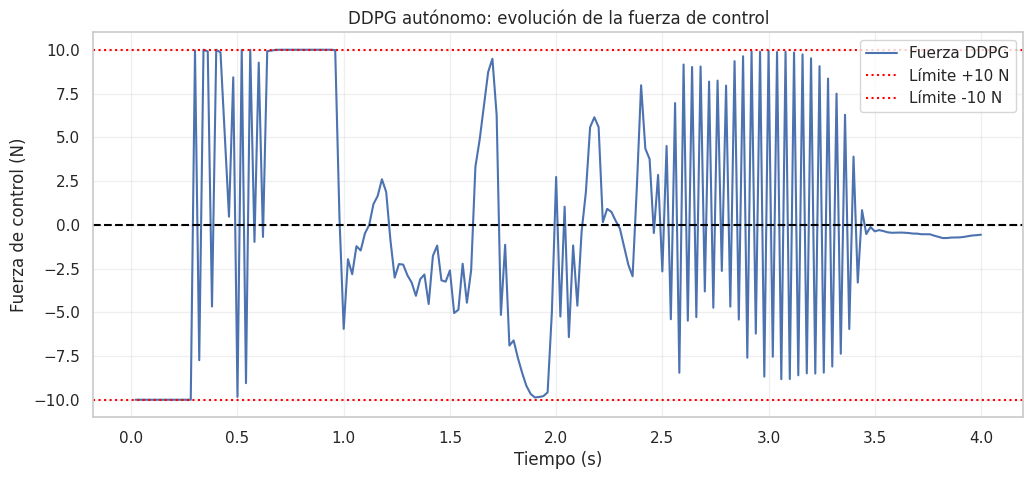

In [ ]:
import matplotlib.pyplot as plt

datos = df[
    (df["metodo"] == "DDPG") &
    (df["semilla"] == 6000) &
    (df["pulso_N"] == 0) &
    (df["time_s"] <= 4)
].sort_values("time_s")

plt.figure(figsize=(12, 5))
plt.plot(datos["time_s"], datos["u_control_N"],
         label="Fuerza DDPG", linewidth=1.5)

plt.axhline(0, color="black", linestyle="--")
plt.axhline(10, color="red", linestyle=":", label="Límite +10 N")
plt.axhline(-10, color="red", linestyle=":", label="Límite -10 N")

plt.xlabel("Tiempo (s)")
plt.ylabel("Fuerza de control (N)")
plt.title("DDPG autónomo: evolución de la fuerza de control")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3. EDA: calidad e integridad
Revisamos ausencia de datos, duplicados de `(id_ensayo, step)` y rangos de las fuerzas. Los vacíos en `tiempo_desde_pulso_s` y diferencias temporales iniciales son esperables y no deben imputarse indiscriminadamente.

In [ ]:
tabla_calidad=pd.DataFrame({'variable':df.columns,'tipo':df.dtypes.astype(str).values,
       'faltantes':df.isna().sum().values,'faltantes_pct':(df.isna().mean()*100).round(3).values,
       'valores_distintos':df.nunique(dropna=True).values})
display(tabla_calidad.sort_values('faltantes',ascending=False).head(20))
print('Duplicados episodio-paso:',int(df.duplicated(['id_ensayo','step']).sum()))
print('Máximo |control|:',df.u_control_N.abs().max(),'N')
print('Máximo |fuerza total|:',df.fuerza_total_N.abs().max(),'N')
error_fuerza=np.abs(df.fuerza_total_N-(df.u_control_N+df.fuerza_perturbacion_N))
print('Máximo error de suma de fuerzas:',error_fuerza.max())
assert df.duplicated(['id_ensayo','step']).sum()==0
assert error_fuerza.max()<1e-5

,variable,tipo,faltantes,faltantes_pct,valores_distintos
41,tiempo_desde_pulso_s,float64,191301,31.883,5501
38,cambio_control_N,float64,100,0.017,545883
39,variacion_theta_rad,float64,100,0.017,172692
40,variacion_omega_rad_s,float64,100,0.017,490833
0,id_ensayo,category,0,0.000,100
5,time_s,float64,0,0.000,6000
6,x_pre,float64,0,0.000,549503
7,v_pre,float64,0,0.000,553515
8,theta_pre,float64,0,0.000,188157
1,metodo,category,0,0.000,5


Duplicados episodio-paso: 0
Máximo |control|: 10.0 N
Máximo |fuerza total|: 14.9402084 N
Máximo error de suma de fuerzas: 4.3700000063040534e-08


## 4. EDA: estadística descriptiva
Se resumen variables físicas y acciones; la media global mezcla fases de *swing-up* y estabilización, por lo que más adelante desagregaremos por arquitectura, pulso y tiempo.

In [ ]:
vars_fisicas=['x','v','theta','omega','u_control_N','fuerza_perturbacion_N','fuerza_total_N','reward']
descriptivos=df[vars_fisicas].describe(percentiles=[.01,.25,.5,.75,.99]).T
display(descriptivos.round(4))

,count,mean,std,min,1%,25%,50%,75%,99%,max
x,600000.0,-0.0231,0.1622,-1.1102,-0.3278,-0.0000,-0.00,0.00,0.5840,1.8188
v,600000.0,-0.0003,0.2109,-2.7625,-0.6230,-0.0000,-0.00,0.00,0.5860,3.4035
theta,600000.0,-0.0016,0.3274,-3.1414,-1.0761,-0.0000,0.00,0.00,0.9115,3.1407
omega,600000.0,-0.0198,0.6955,-8.1733,-2.3246,-0.0000,-0.00,0.00,1.1970,8.6147
u_control_N,600000.0,-0.0074,2.2915,-10.0000,-5.0146,-0.0000,0.00,0.00,5.0079,10.0000
fuerza_perturbacion_N,600000.0,0.0071,0.2317,0.0000,0.0000,0.0000,0.00,0.00,0.0000,10.0000
fuerza_total_N,600000.0,-0.0003,2.2853,-10.0000,-5.0138,-0.0000,0.00,0.00,5.0080,14.9402
reward,600000.0,4.8983,0.8056,-1.6469,-0.0469,5.0462,5.05,5.05,5.0500,5.0500


### 4.1 Distribuciones y valores extremos
Los histogramas permiten identificar sesgos, saturación y concentraciones cerca del equilibrio. La muestra aleatoria se emplea **solo para graficar**; las estadísticas descriptivas anteriores usan todos los registros.

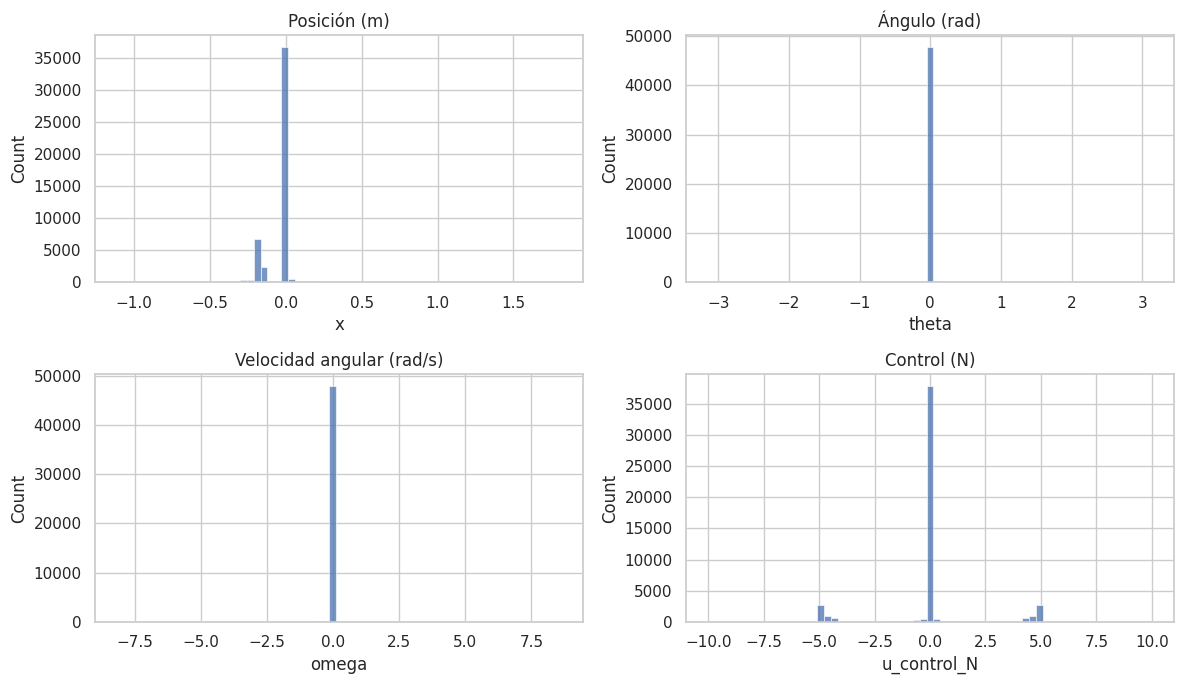

In [ ]:
muestra=df.sample(n=min(len(df),50000),random_state=23)
fig,axs=plt.subplots(2,2,figsize=(12,7))
for ax,var,nombre in zip(axs.flat,['x','theta','omega','u_control_N'],
       ['Posición (m)','Ángulo (rad)','Velocidad angular (rad/s)','Control (N)']):
    sns.histplot(data=muestra,x=var,bins=65,ax=ax)
    ax.set_title(nombre)
plt.tight_layout();plt.show()

## 5. EDA: correlaciones
Pearson cuantifica asociación lineal; no establece causalidad. Las columnas derivadas pueden mostrar correlación elevada porque se construyen algebraicamente a partir del estado original.

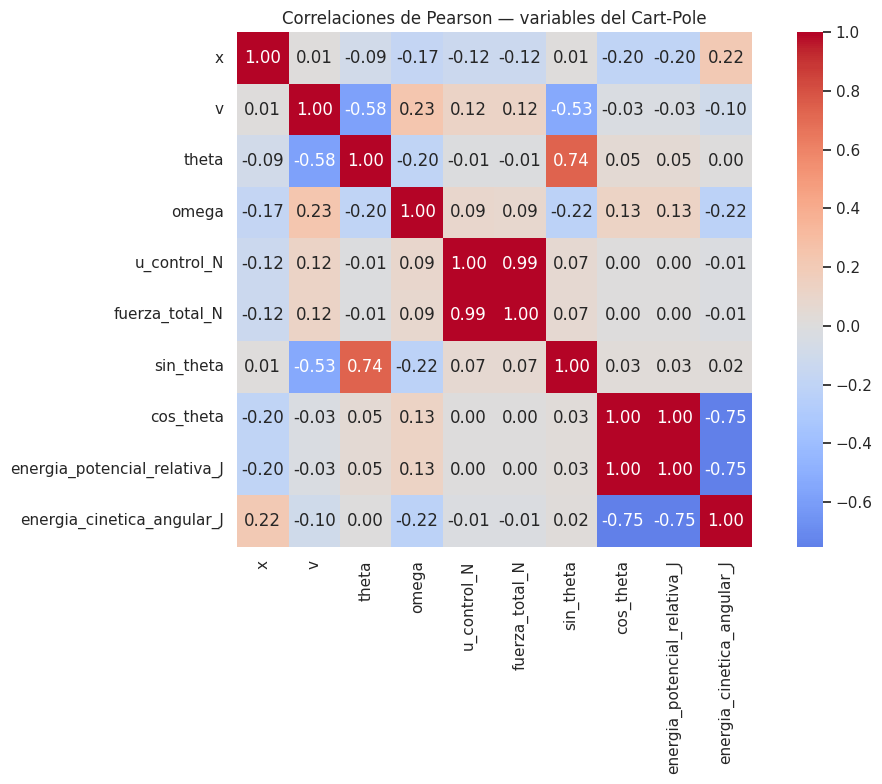

In [ ]:
cols_corr=['x','v','theta','omega','u_control_N','fuerza_total_N','sin_theta','cos_theta','energia_potencial_relativa_J','energia_cinetica_angular_J']
matriz=df[cols_corr].corr(method='pearson')
plt.figure(figsize=(11,8));sns.heatmap(matriz,annot=True,fmt='.2f',cmap='coolwarm',center=0,square=True)
plt.title('Correlaciones de Pearson — variables del Cart-Pole');plt.tight_layout();plt.show()

## 6. EDA comparativo: arquitecturas y perturbaciones
La **ocupación estable** es la proporción de pasos dentro de la región estricta: |x|≤0,20 m, |v|≤0,10 m/s, |θ|≤0,05 rad y |ω|≤0,10 rad/s.

**Importante:** resumimos primero cada episodio; no tratamos los 600.000 pasos como réplicas estadísticas independientes.

In [ ]:
episodios=df.groupby(['id_ensayo','metodo','pulso_N','semilla'],observed=True).agg(
    n_pasos=('step','size'),ocupacion_pct=('estable_estricto',lambda x:100*x.mean()),
    rmse_theta_rad=('theta',lambda x:float(np.sqrt(np.mean(x.to_numpy()**2)))),
    esfuerzo_N2s=('u_control_N',lambda x:float(np.sum(x.to_numpy()**2)*.02)),
    conmutaciones=('conmutacion','sum')).reset_index()
resumen=episodios.groupby(['metodo','pulso_N'],observed=True).agg(
    n_episodios=('id_ensayo','size'),ocupacion_media_pct=('ocupacion_pct','mean'),
    ocupacion_sd=('ocupacion_pct','std'),rmse_theta_media=('rmse_theta_rad','mean'),
    esfuerzo_medio_N2s=('esfuerzo_N2s','mean')).reset_index()
display(resumen.round(3))

,metodo,pulso_N,n_episodios,ocupacion_media_pct,ocupacion_sd,rmse_theta_media,esfuerzo_medio_N2s
0,DDPG,0,5,89.963,0.884,0.302,2696.030
1,DDPG,2,5,86.613,0.884,0.302,2614.732
2,DDPG,5,5,86.297,0.884,0.302,2613.719
3,DDPG,10,5,84.403,0.881,0.302,2588.811
4,DDPG_ISMC,0,5,95.333,0.373,0.302,165.952
5,DDPG_ISMC,2,5,95.217,0.373,0.302,167.083
6,DDPG_ISMC,5,5,93.800,0.373,0.302,173.437
7,DDPG_ISMC,10,5,92.750,0.373,0.302,195.340
8,DDPG_LQR,0,5,95.860,0.549,0.302,166.203
9,DDPG_LQR,2,5,95.343,0.549,0.302,167.307


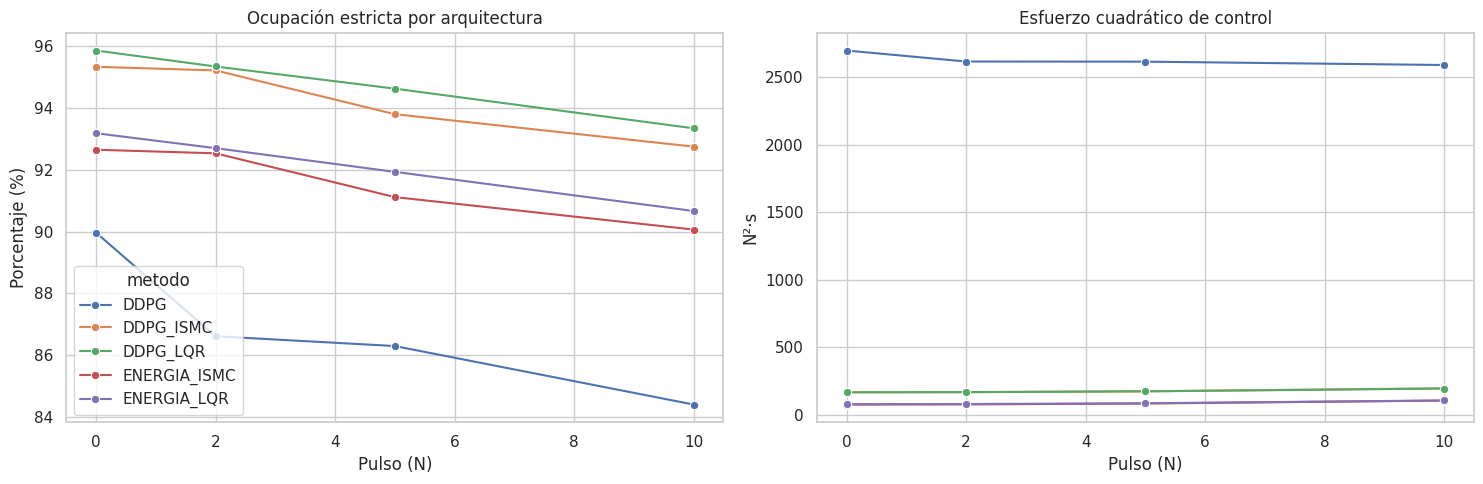

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(15,5))
sns.lineplot(data=resumen,x='pulso_N',y='ocupacion_media_pct',hue='metodo',marker='o',ax=axs[0])
sns.lineplot(data=resumen,x='pulso_N',y='esfuerzo_medio_N2s',hue='metodo',marker='o',ax=axs[1],legend=False)
axs[0].set(title='Ocupación estricta por arquitectura',ylabel='Porcentaje (%)',xlabel='Pulso (N)')
axs[1].set(title='Esfuerzo cuadrático de control',ylabel='N²·s',xlabel='Pulso (N)')
plt.tight_layout();plt.show()

### 6.1 Trayectoria representativa y etapas temporales
Se muestra **un único episodio**, evitando mezclar distintas semillas. Las franjas 0–10, 10–30 y 30–120 s sirven para inspección; no equivalen automáticamente a modos reales del supervisor.

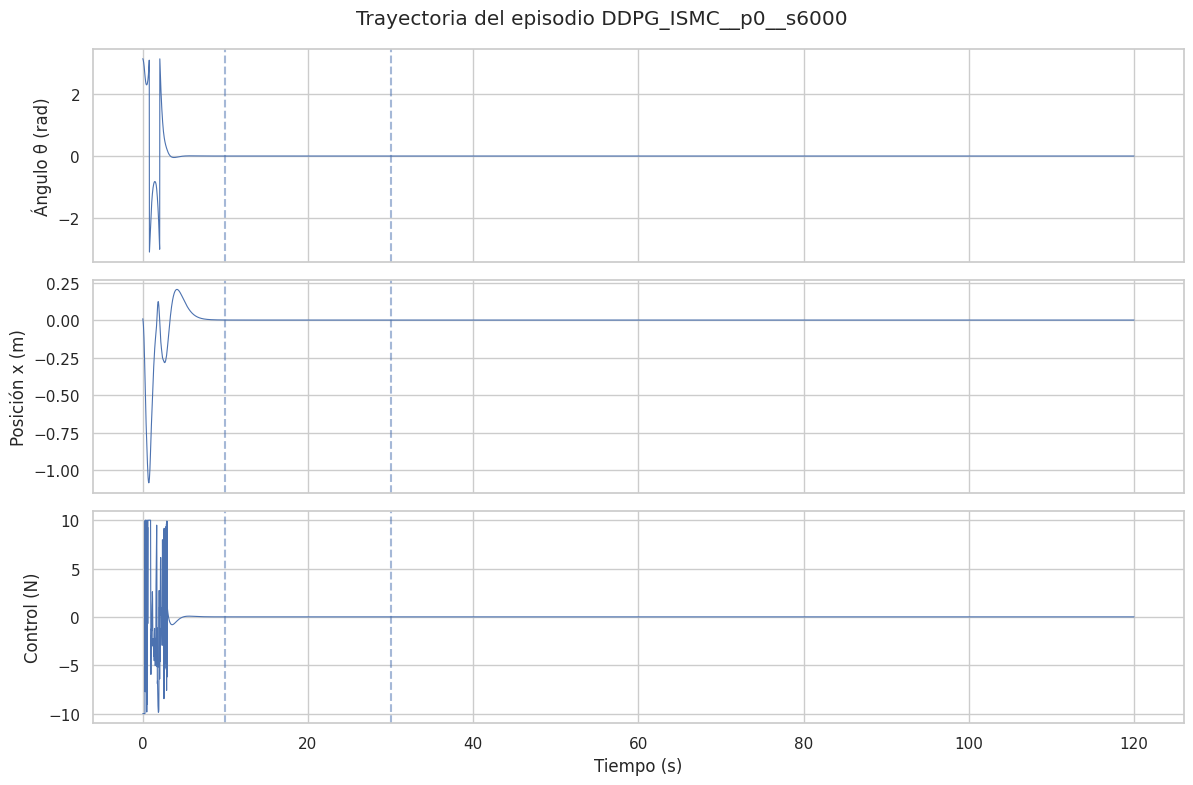

In [ ]:
ej=df.loc[df.id_ensayo==df.id_ensayo.cat.categories[0],['time_s','theta','x','u_control_N']]
fig,axes=plt.subplots(3,1,figsize=(12,8),sharex=True)
for ax,(col,nombre) in zip(axes,[('theta','Ángulo θ (rad)'),('x','Posición x (m)'),('u_control_N','Control (N)')]):
    ax.plot(ej.time_s,ej[col],linewidth=.8);ax.set_ylabel(nombre)
    for t in (10,30):ax.axvline(t,ls='--',alpha=.5)
axes[-1].set_xlabel('Tiempo (s)');fig.suptitle('Trayectoria del episodio '+str(df.id_ensayo.cat.categories[0]));plt.tight_layout();plt.show()

## 7. Matriz de confusión — **tarea auxiliar de clasificación**
La tesis utiliza **DDPG para control continuo** y **Ridge / HistGradientBoosting para regresión**. Por tanto, una matriz de confusión no corresponde a los errores de regresión, sino a una pregunta distinta:

**¿Podemos clasificar si el siguiente estado del péndulo quedará dentro de la región de estabilidad estricta?**

Construimos un clasificador demostrativo sobre **entradas previas al paso** (`x_pre`, `v_pre`, `theta_pre`, `omega_pre`, acción y perturbación conocidas en *t*). La etiqueta `estable_estricto` se calcula en el estado *posterior*. No usamos etiquetas posteriores como entradas. Reservamos la semilla 6004 para la prueba; el desequilibrio entre clases se reporta explícitamente. Esta clasificación **no prueba un mejor desempeño de DDPG**.

Distribución de clases en train:


,fracción
estable_estricto,
1,0.917892
0,0.082108


Distribución de clases en test:


,fracción
estable_estricto,
1,0.9177
0,0.0823


Balanced accuracy: 0.9961 | F1 clase estable: 0.9994
                 precision    recall  f1-score   support

Fuera de región       0.99      0.99      0.99      2469
      En región       1.00      1.00      1.00     27531

       accuracy                           1.00     30000
      macro avg       1.00      1.00      1.00     30000
   weighted avg       1.00      1.00      1.00     30000



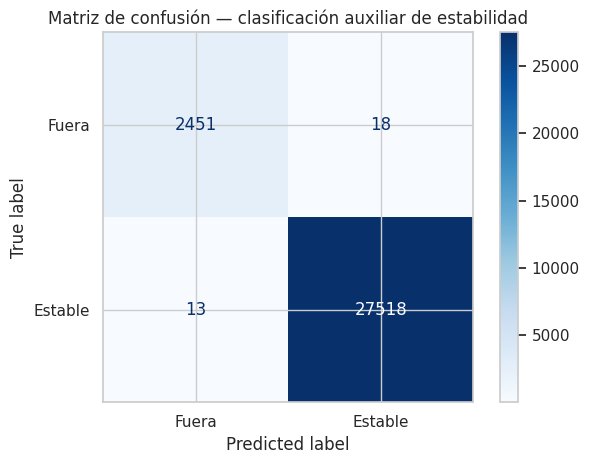

In [ ]:
entradas_clas=['x_pre','v_pre','theta_pre','omega_pre','u_control_N','fuerza_perturbacion_N']
# Muestra reproducible por semilla, mantiene episodios íntegros en particiones de train/test
train=df[df.semilla.isin([6000,6001,6002,6003])].sample(n=65000,random_state=23)
test=df[df.semilla==6004].sample(n=min(30000,(df.semilla==6004).sum()),random_state=23)
Xtr=train[entradas_clas]; ytr=train['estable_estricto'].astype(int)
Xte=test[entradas_clas]; yte=test['estable_estricto'].astype(int)
print('Distribución de clases en train:');display(ytr.value_counts(normalize=True).rename('fracción'))
print('Distribución de clases en test:');display(yte.value_counts(normalize=True).rename('fracción'))
clf=HistGradientBoostingClassifier(max_iter=80,max_leaf_nodes=15,learning_rate=.1,random_state=23)
clf.fit(Xtr,ytr)
pred=clf.predict(Xte)
print('Balanced accuracy:',round(balanced_accuracy_score(yte,pred),4),'| F1 clase estable:',round(f1_score(yte,pred,zero_division=0),4))
print(classification_report(yte,pred,target_names=['Fuera de región','En región'],zero_division=0))
ConfusionMatrixDisplay.from_predictions(yte,pred,display_labels=['Fuera','Estable'],cmap='Blues',values_format='d')
plt.title('Matriz de confusión — clasificación auxiliar de estabilidad');plt.tight_layout();plt.show()

**Interpretación de la matriz:** la diagonal son aciertos; las celdas fuera de diagonal son errores. Una elevada exactitud puede engañar cuando predominan estados estables; por eso se informa también la exactitud balanceada y el *recall* de cada clase. **Este experimento no sustituye la validación de regresión ni una evaluación de robustez de control.**

## 8. Ingeniería de características (Feature Engineering)
Se derivan variables con significado físico para facilitar la representación matemática del sistema. **Crítico:** las columnas existentes `sin_theta`, `cos_theta` y energías de este archivo describen el estado **posterior**. Son legítimas para EDA, pero **no** debemos usarlas como predictoras de ese mismo estado; para una predicción causal hay que calcularlas desde las columnas `*_pre`.

In [ ]:
# Ejemplo pedagógico causal: se calculan desde el estado ANTES de ejecutar la acción.
# Parámetros nominales: m = 0.1 kg; M = 1.0 kg; l = 0.5 m; L = 1.0 m
m=0.1; M=1.0; l=.5; L=1.; g=9.81
I=m*L**2/12; Jp=I+m*l*l
vista_fe=df.head(10)[['x_pre','v_pre','theta_pre','omega_pre','u_control_N','fuerza_perturbacion_N']].copy()
vista_fe['sin_theta_pre']=np.sin(vista_fe.theta_pre)
vista_fe['cos_theta_pre']=np.cos(vista_fe.theta_pre)
vista_fe['energia_potencial_pre_J']=m*g*l*(np.cos(vista_fe.theta_pre)-1)
vista_fe['energia_cinetica_angular_pre_J']=.5*Jp*vista_fe.omega_pre**2
vista_fe['energia_cinetica_carro_pre_J']=.5*M*vista_fe.v_pre**2
vista_fe['margen_riel_pre_m']=2.4-vista_fe.x_pre.abs()
display(vista_fe.round(5))

,x_pre,v_pre,theta_pre,omega_pre,u_control_N,fuerza_perturbacion_N,sin_theta_pre,cos_theta_pre,energia_potencial_pre_J,energia_cinetica_angular_pre_J,energia_cinetica_carro_pre_J,margen_riel_pre_m
0,0.01178,0.04825,3.13734,-0.02306,-10.0,0,0.00425,-0.99999,-0.98100,0.00001,0.00116,2.38822
1,0.00885,-0.14681,3.13105,-0.31439,-10.0,0,0.01054,-0.99994,-0.98097,0.00165,0.01078,2.39115
2,0.00201,-0.34178,3.11898,-0.60373,-10.0,0,0.02261,-0.99974,-0.98087,0.00607,0.05841,2.39799
3,-0.00872,-0.53656,3.10120,-0.88917,-10.0,0,0.04039,-0.99918,-0.98060,0.01318,0.14395,2.39128
4,-0.02334,-0.73105,3.07782,-1.16878,-10.0,0,0.06373,-0.99797,-0.98000,0.02277,0.26722,2.37666
5,-0.04184,-0.92512,3.04901,-1.44053,-10.0,0,0.09245,-0.99572,-0.97890,0.03459,0.42792,2.35816
6,-0.06422,-1.11861,3.01496,-1.70232,-10.0,0,0.12629,-0.99199,-0.97707,0.04830,0.62564,2.33578
7,-0.09044,-1.31135,2.97592,-1.95195,-10.0,0,0.16491,-0.98631,-0.97428,0.06350,0.85982,2.30956
8,-0.12051,-1.50314,2.93218,-2.18717,-10.0,0,0.20788,-0.97815,-0.97028,0.07973,1.12972,2.27949
9,-0.15438,-1.69377,2.88407,-2.40568,-10.0,0,0.25469,-0.96702,-0.96482,0.09646,1.43443,2.24562


### 8.1 Comprobación matemática de características
Verificamos que las transformaciones coinciden con sus definiciones, sin tratarlas como nueva evidencia independiente.

In [ ]:
max_error_seno=np.max(np.abs(df.sin_theta.to_numpy()-np.sin(df.theta.to_numpy())))
max_error_cos=np.max(np.abs(df.cos_theta.to_numpy()-np.cos(df.theta.to_numpy())))
max_error_riel=np.max(np.abs(df.distancia_riel_m.to_numpy()-(2.4-np.abs(df.x.to_numpy()))))
print('Error máximo seno:',max_error_seno)
print('Error máximo coseno:',max_error_cos)
print('Error máximo margen al riel:',max_error_riel)
assert max_error_seno<1e-5 and max_error_cos<1e-5 and max_error_riel<1e-4

Error máximo seno: 5.08684386280045e-09
Error máximo coseno: 5.177042655679642e-09
Error máximo margen al riel: 5.000000413701855e-09


## 9. Diseño experimental — Baseline + 2 variantes de los DATOS
**Hipótesis:** incorporar características con fundamento físico y temporal permite disminuir el error de predicción de la dinámica frente a un conjunto de variables originales.

**Tarea supervisada:** regresión a un paso de `delta_v_m_s` y `delta_omega_rad_s` (diferencias entre estado posterior y previo).

| Tratamiento experimental | Etiqueta en el CSV | Cambio realizado |
|---|---|---|
| **Baseline** | `Base` | Variables originales previas a la transición y señales de fuerza |
| **Variante 1** | `FE_fisica` | Ampliación del conjunto de entrada con características físicas |
| **Variante 2** | `FE_temporal` | Ampliación con información física y temporal causal |

**Variables de control:** los algoritmos permanecen constantes entre conjuntos (**Ridge** e **HistGradientBoosting**). La comparación se realiza bajo el mismo protocolo LOSO (se entrenó con cuatro semillas y se evaluó en una semilla reservada, cinco repeticiones). Los resultados se leen del CSV obtenido en el experimento ya ejecutado; **no debe interpretarse esta lectura como un nuevo entrenamiento**.

**Prevención de fuga de datos:** los predictores derivados del estado deben construirse exclusivamente a partir del estado previo (`*_pre`) y de información disponible al momento de la acción. La agrupación por semilla reduce la dependencia entre conjuntos de entrenamiento y prueba, aunque no equivale a una validación externa en un sistema físico.

### 9.1 Resultados de validación de Feature Engineering con Ridge y HistGradientBoosting
Se presentan los **resultados experimentales de regresión ya ejecutados** usando validación cruzada *Leave-One-Seed-Out*. Cada fold entrena con cuatro semillas y evalúa en la quinta; esto no significa cinco conjuntos de entrenamiento independientes.

Suba `metricas_5_folds.csv` a la misma carpeta para ver los resultados. **No se simulan números si el archivo falta.** Los objetivos son `v_post−v_pre` y `omega_post−omega_pre`.

Sube el archivo metricas_5_folds.csv


Saving metricas_5_folds.csv to metricas_5_folds.csv


,semilla_prueba,modelo,conjunto,objetivo,n_features,n_train,n_test,MAE,RMSE
0,6000,Ridge,Base,delta_v_m_s,6,40000,120000,0.000467,0.002190
1,6000,Ridge,Base,delta_omega_rad_s,6,40000,120000,0.014329,0.051540
2,6000,Ridge,FE_fisica,delta_v_m_s,15,40000,120000,0.000150,0.000607
3,6000,Ridge,FE_fisica,delta_omega_rad_s,15,40000,120000,0.000347,0.001686
4,6000,Ridge,FE_temporal,delta_v_m_s,21,40000,120000,0.000136,0.000510
5,6000,Ridge,FE_temporal,delta_omega_rad_s,21,40000,120000,0.000291,0.001620
6,6000,HistGradientBoosting,Base,delta_v_m_s,6,40000,120000,0.000443,0.002637
7,6000,HistGradientBoosting,Base,delta_omega_rad_s,6,40000,120000,0.001583,0.008170
8,6000,HistGradientBoosting,FE_fisica,delta_v_m_s,15,40000,120000,0.000350,0.001935
9,6000,HistGradientBoosting,FE_fisica,delta_omega_rad_s,15,40000,120000,0.000756,0.003718


Evaluaciones: 60 | Folds: 5


,modelo,conjunto,objetivo,rmse_medio,rmse_sd,mae_medio
0,HistGradientBoosting,Base,delta_omega_rad_s,0.009818,0.004399,0.001845
1,HistGradientBoosting,Base,delta_v_m_s,0.002968,0.000804,0.000494
2,HistGradientBoosting,FE_fisica,delta_omega_rad_s,0.004890,0.001733,0.000927
3,HistGradientBoosting,FE_fisica,delta_v_m_s,0.002394,0.000495,0.000399
4,HistGradientBoosting,FE_temporal,delta_omega_rad_s,0.004836,0.001509,0.000893
5,HistGradientBoosting,FE_temporal,delta_v_m_s,0.002370,0.000515,0.000388
6,Ridge,Base,delta_omega_rad_s,0.051368,0.000671,0.015239
7,Ridge,Base,delta_v_m_s,0.002197,0.000010,0.000455
8,Ridge,FE_fisica,delta_omega_rad_s,0.001655,0.000066,0.000343
9,Ridge,FE_fisica,delta_v_m_s,0.000612,0.000016,0.000158


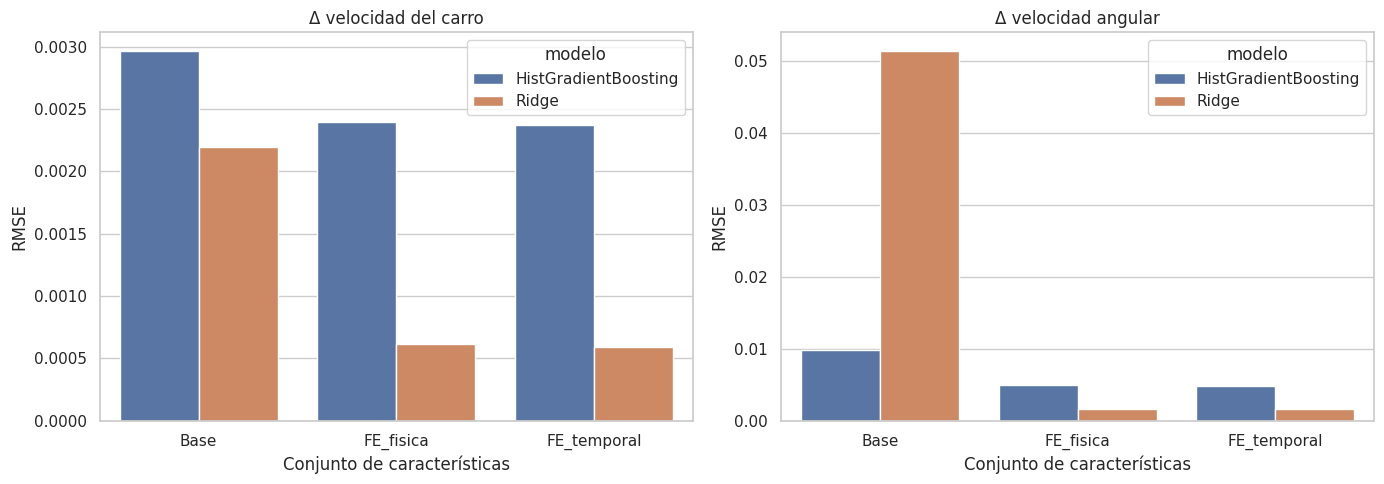

In [ ]:
from pathlib import Path
from google.colab import files

# Buscar el archivo en el almacenamiento temporal de Colab
ruta_folds = Path('/content/metricas_5_folds.csv')

# Si no existe, solicitar su carga desde Windows
if not ruta_folds.is_file():
    print("Sube el archivo metricas_5_folds.csv")
    files.upload()

# Verificar nuevamente
ruta_folds = (
    Path('/content/metricas_5_folds.csv')
    if Path('/content/metricas_5_folds.csv').is_file()
    else None
)
if ruta_folds is None:
    raise FileNotFoundError('Falta metricas_5_folds.csv: súbalo a /content antes de continuar.')
else:
    cv=pd.read_csv(ruta_folds)
    display(cv.head(10))
    print('Evaluaciones:',len(cv),'| Folds:',cv.semilla_prueba.nunique())
    resumen_cv=cv.groupby(['modelo','conjunto','objetivo'],as_index=False).agg(rmse_medio=('RMSE','mean'),rmse_sd=('RMSE','std'),mae_medio=('MAE','mean'))
    display(resumen_cv.round(6))
    fig,axs=plt.subplots(1,2,figsize=(14,5))
    for ax,objetivo,titulo in zip(axs,['delta_v_m_s','delta_omega_rad_s'],['Δ velocidad del carro','Δ velocidad angular']):
        sub=resumen_cv[resumen_cv.objetivo==objetivo]
        sns.barplot(data=sub,x='conjunto',y='rmse_medio',hue='modelo',ax=ax)
        ax.set(title=titulo,ylabel='RMSE',xlabel='Conjunto de características')
    plt.tight_layout();plt.show()

### 9.2 Consistencia entre semillas
Comparamos el error de cada semilla antes y después de agregar FE. Usamos la **semilla** como unidad de comparación; no se declara significancia sobre 120.000 filas correlacionadas.

In [ ]:
# VALIDACIÓN CRUZADA DE FEATURE ENGINEERING
# Comparación entre modelo Base y FE_temporal

base = cv[cv["conjunto"] == "Base"][
    ["semilla_prueba", "modelo", "objetivo", "RMSE"]
].rename(columns={"RMSE": "rmse_base"})

temporal = cv[cv["conjunto"] == "FE_temporal"][
    ["semilla_prueba", "modelo", "objetivo", "RMSE"]
].rename(columns={"RMSE": "rmse_temporal"})

# Emparejar resultados por semilla, algoritmo y objetivo
pares = base.merge(
    temporal,
    on=["semilla_prueba", "modelo", "objetivo"],
    validate="one_to_one"
)

# Porcentaje de reducción del error
pares["mejora_pct"] = (
    100 * (pares["rmse_base"] - pares["rmse_temporal"])
    / pares["rmse_base"]
)

print("VALIDACIÓN CRUZADA: RESULTADOS POR SEMILLA")
display(pares.round(5))

print("\nRESUMEN DE MEJORA POR ALGORITMO Y OBJETIVO")

resumen_mejoras = pares.groupby(
    ["modelo", "objetivo"]
)["mejora_pct"].agg(["mean", "min", "max"])

display(resumen_mejoras.round(2))

VALIDACIÓN CRUZADA: RESULTADOS POR SEMILLA


,semilla_prueba,modelo,objetivo,rmse_base,rmse_temporal,mejora_pct
0,6000,Ridge,delta_v_m_s,0.00219,0.00051,76.69459
1,6000,Ridge,delta_omega_rad_s,0.05154,0.00162,96.85685
2,6000,HistGradientBoosting,delta_v_m_s,0.00264,0.00193,26.74800
3,6000,HistGradientBoosting,delta_omega_rad_s,0.00817,0.00376,53.96547
4,6001,Ridge,delta_v_m_s,0.00219,0.00057,74.12927
5,6001,Ridge,delta_omega_rad_s,0.05124,0.00163,96.82077
6,6001,HistGradientBoosting,delta_v_m_s,0.00256,0.00218,14.78398
7,6001,HistGradientBoosting,delta_omega_rad_s,0.00732,0.00417,42.98068
8,6002,Ridge,delta_v_m_s,0.00220,0.00053,75.71026
9,6002,Ridge,delta_omega_rad_s,0.05077,0.00164,96.77172



RESUMEN DE MEJORA POR ALGORITMO Y OBJETIVO


mean    min    max
modelo               objetivo                              
HistGradientBoosting delta_omega_rad_s  48.94  42.98  57.58
                     delta_v_m_s        19.29  12.45  26.75
Ridge                delta_omega_rad_s  96.85  96.77  97.02
                     delta_v_m_s        73.27  63.94  76.69

In [ ]:
print("Conjuntos disponibles:")
print(cv['conjunto'].unique())

print("\nModelos disponibles:")
print(cv['modelo'].unique())

print("\nTotal de filas:", len(cv))

Conjuntos disponibles:
['Base' 'FE_fisica' 'FE_temporal']

Modelos disponibles:
['Ridge' 'HistGradientBoosting']

Total de filas: 60


### 9.3 Tabla experimental: mismo algoritmo, tres representaciones de datos
Se muestran los RMSE por modelo y objetivo, promediados sobre los **cinco folds**, y la desviación estándar entre semillas. **Menor RMSE indica mejor predicción.** No se comparan directamente RMSE de objetivos con unidades diferentes.

In [ ]:
orden_conjuntos = ['Base','FE_fisica','FE_temporal']
requeridas_cv = {'semilla_prueba','modelo','conjunto','objetivo','RMSE'}
assert requeridas_cv.issubset(cv.columns), f'Faltan columnas: {requeridas_cv-set(cv.columns)}'
assert set(orden_conjuntos).issubset(set(cv['conjunto'].unique())), 'Falta alguno de los tres conjuntos experimentales.'

tabla_experimentos = (
    cv.groupby(['modelo','objetivo','conjunto'],as_index=False)
      .agg(RMSE_medio=('RMSE','mean'),RMSE_sd=('RMSE','std'),n_folds=('RMSE','size'))
)
tabla_experimentos['conjunto'] = pd.Categorical(
    tabla_experimentos['conjunto'],categories=orden_conjuntos,ordered=True
)
tabla_experimentos = tabla_experimentos.sort_values(['objetivo','modelo','conjunto'])
assert (tabla_experimentos.n_folds==5).all(), 'Revisar folds faltantes o duplicados.'
print('RESULTADOS EXPERIMENTALES: BASELINE / FE FÍSICA / FE TEMPORAL')
display(tabla_experimentos.round(6))

RESULTADOS EXPERIMENTALES: BASELINE / FE FÍSICA / FE TEMPORAL


,modelo,objetivo,conjunto,RMSE_medio,RMSE_sd,n_folds
0,HistGradientBoosting,delta_omega_rad_s,Base,0.009818,0.004399,5
1,HistGradientBoosting,delta_omega_rad_s,FE_fisica,0.004890,0.001733,5
2,HistGradientBoosting,delta_omega_rad_s,FE_temporal,0.004836,0.001509,5
6,Ridge,delta_omega_rad_s,Base,0.051368,0.000671,5
7,Ridge,delta_omega_rad_s,FE_fisica,0.001655,0.000066,5
8,Ridge,delta_omega_rad_s,FE_temporal,0.001617,0.000030,5
3,HistGradientBoosting,delta_v_m_s,Base,0.002968,0.000804,5
4,HistGradientBoosting,delta_v_m_s,FE_fisica,0.002394,0.000495,5
5,HistGradientBoosting,delta_v_m_s,FE_temporal,0.002370,0.000515,5
9,Ridge,delta_v_m_s,Base,0.002197,0.000010,5


### 9.4 Visualización separada por objetivo
Las barras ilustran el RMSE promedio de las cinco semillas. La escala vertical es distinta entre objetivos, por lo que deben interpretarse **por separado**.

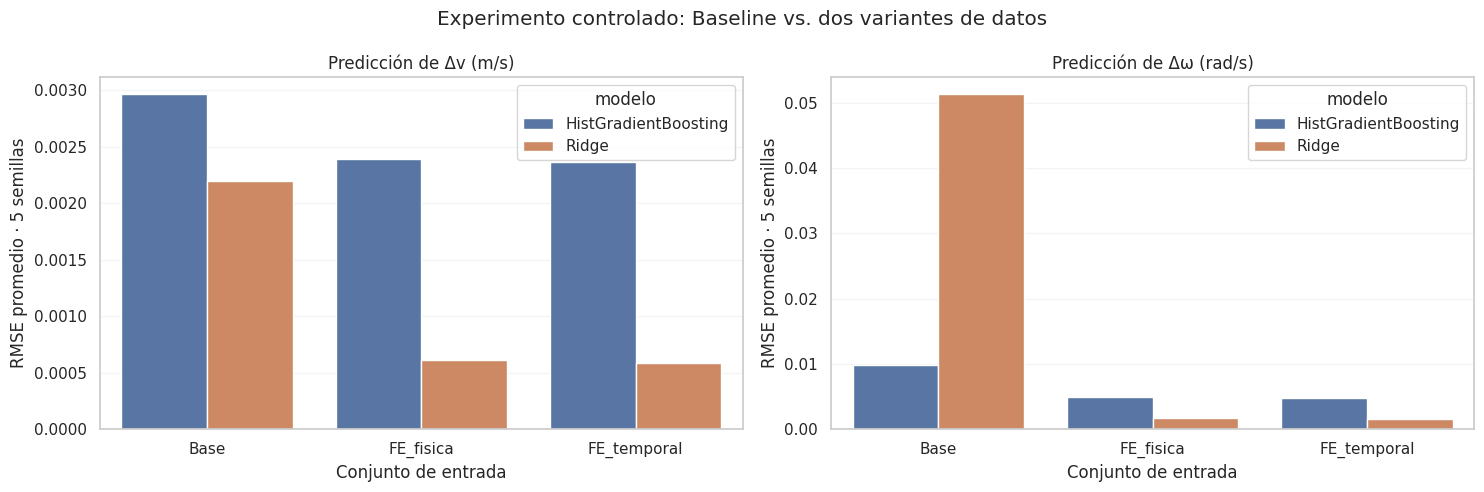

In [ ]:
fig, axs = plt.subplots(1,2,figsize=(15,5))
objetivos=[('delta_v_m_s','Predicción de Δv (m/s)'),('delta_omega_rad_s','Predicción de Δω (rad/s)')]
for ax,(objetivo,titulo) in zip(axs,objetivos):
    sub=tabla_experimentos[tabla_experimentos.objetivo==objetivo]
    sns.barplot(data=sub,x='conjunto',y='RMSE_medio',hue='modelo',order=orden_conjuntos,ax=ax)
    ax.set(title=titulo,xlabel='Conjunto de entrada',ylabel='RMSE promedio · 5 semillas')
    ax.grid(axis='y',alpha=.2)
plt.suptitle('Experimento controlado: Baseline vs. dos variantes de datos')
plt.tight_layout()
plt.show()

### 9.5 Mejora porcentual emparejada por semilla
Para cada semilla, modelo y objetivo, calculamos la reducción: **100 × (RMSE Base − RMSE Variante) / RMSE Base**.

Después se informa el **promedio de los porcentajes por semilla**. Esta cantidad no tiene por qué coincidir con el porcentaje calculado a partir de los RMSE medios.

In [ ]:
ancha = cv.pivot_table(index=['semilla_prueba','modelo','objetivo'],columns='conjunto',values='RMSE',aggfunc='first').reset_index()
assert ancha[orden_conjuntos].notna().all().all(), 'Faltan resultados para un par semilla/modelo/objetivo.'
assert (ancha['Base']>0).all(), 'No puede calcularse el porcentaje con RMSE Base igual a cero.'
mejoras_variantes=ancha[['semilla_prueba','modelo','objetivo']].copy()
for variante in ['FE_fisica','FE_temporal']:
    mejoras_variantes[f'reduccion_rmse_{variante}_pct']=100*(ancha['Base']-ancha[variante])/ancha['Base']
resumen_mejoras_variantes=(
    mejoras_variantes.groupby(['modelo','objetivo'],as_index=False)
    .agg(mejora_fisica_pct=('reduccion_rmse_FE_fisica_pct','mean'),
         mejora_temporal_pct=('reduccion_rmse_FE_temporal_pct','mean'))
)
print('REDUCCIÓN DEL RMSE RESPECTO AL BASELINE · PROMEDIO DE CINCO SEMILLAS')
display(resumen_mejoras_variantes.round(2))
print('DETALLE EMPAREJADO POR SEMILLA')
display(mejoras_variantes.round(3))

REDUCCIÓN DEL RMSE RESPECTO AL BASELINE · PROMEDIO DE CINCO SEMILLAS


,modelo,objetivo,mejora_fisica_pct,mejora_temporal_pct
0,HistGradientBoosting,delta_omega_rad_s,48.87,48.94
1,HistGradientBoosting,delta_v_m_s,18.32,19.29
2,Ridge,delta_omega_rad_s,96.78,96.85
3,Ridge,delta_v_m_s,72.17,73.27


DETALLE EMPAREJADO POR SEMILLA


conjunto,semilla_prueba,modelo,objetivo,reduccion_rmse_FE_fisica_pct,reduccion_rmse_FE_temporal_pct
0,6000,HistGradientBoosting,delta_omega_rad_s,54.486,53.965
1,6000,HistGradientBoosting,delta_v_m_s,26.607,26.748
2,6000,Ridge,delta_omega_rad_s,96.729,96.857
3,6000,Ridge,delta_v_m_s,72.310,76.695
4,6001,HistGradientBoosting,delta_omega_rad_s,42.010,42.981
5,6001,HistGradientBoosting,delta_v_m_s,14.047,14.784
6,6001,Ridge,delta_omega_rad_s,96.728,96.821
7,6001,Ridge,delta_v_m_s,72.299,74.129
8,6002,HistGradientBoosting,delta_omega_rad_s,48.693,44.411
9,6002,HistGradientBoosting,delta_v_m_s,11.990,12.447


### 9.6 Interpretación del experimento y validez
- Una reducción positiva del RMSE evidencia beneficio de la representación de los datos **en la tarea de predicción a un paso**; no demuestra una mejora del desempeño del agente DDPG.
- El control metodológico principal es **mantener el algoritmo y la unidad de evaluación (semilla) constantes** al comparar Base, FE física y FE temporal.
- Con cinco semillas, las diferencias son **exploratorias**. Un contraste bilateral exacto por signos no puede producir `p < 0,05` con solo cinco pares concordantes (`p mínimo = 0,0625`).
- La base procede de simulación. La generalización ante distintos parámetros físicos, sensores reales o bancos físicos es una pregunta pendiente.

## 10. Conclusiones para la entrega y exposición
**EDA.** Se analizaron calidad, valores faltantes, distribuciones, correlaciones, dinámica temporal, ocupación estricta de estabilidad y perturbaciones en cinco arquitecturas de control. Las comparaciones de controladores se calcularon primero por episodio y luego se resumieron por arquitectura y escenario.

**Feature Engineering.** Se estudiaron transformaciones trigonométricas, de energía y proximidad a límites del riel. Las características destinadas a predecir un paso futuro deben calcularse desde el estado **previo**, para evitar fuga de información.

**Baseline y variantes.** Los resultados importados de validación LOSO comparan `Base`, `FE_fisica` y `FE_temporal` con Ridge e HistGradientBoosting, manteniendo el algoritmo constante para evaluar el efecto de los **datos**. Las tablas de RMSE y reducciones porcentuales aportan la evidencia cuantitativa; las diferencias deben interpretarse por objetivo y por semilla.

**Alcance.** Los resultados de regresión sobre la dinámica a un paso **no prueban** una mejora de la política de control DDPG; tampoco sustituyen validación física, más semillas o análisis de sensibilidad.

**Punto central para el profesor:** el experimento cambia los conjuntos de características, no las arquitecturas ni los hiperparámetros de los modelos usados para compararlas.

## 11. Guardado y entrega
El CSV principal se mantiene intacto. Se exportan por separado las métricas de controladores (`resumen`), calidad del dataset y resultados Baseline/variantes; así se evita sobrescribir la comparación de arquitecturas con la tabla de mejoras.

**Para entregar:** guardar el cuaderno en Drive (`Ctrl + S`), descargar el `.ipynb` y opcionalmente descargar el ZIP generado abajo. El `.ipynb` conserva las salidas visibles guardadas, pero los archivos temporales `/content` no persisten al terminar el runtime.

In [ ]:
from pathlib import Path
import shutil

salida = Path('/content/CartPole_resultados_colab')
salida.mkdir(parents=True, exist_ok=True)

tabla_calidad.to_csv(salida/'calidad_datos.csv', index=False)
resumen.to_csv(salida/'comparacion_arquitecturas.csv', index=False)
episodios.to_csv(salida/'metricas_por_episodio.csv', index=False)
resumen_cv.to_csv(salida/'validacion_cruzada_resumen.csv', index=False)
tabla_experimentos.to_csv(salida/'baseline_y_variantes_rmse.csv', index=False)
mejoras_variantes.to_csv(salida/'mejoras_variantes_por_semilla.csv', index=False)
resumen_mejoras_variantes.to_csv(salida/'mejoras_variantes_resumen.csv', index=False)

print('Archivos generados:')
for p in sorted(salida.glob('*.csv')):
    print(' -',p.name, '|',p.stat().st_size,'bytes')

zip_path = shutil.make_archive('/content/CartPole_EDA_FE_Resultados_Profesor', 'zip', root_dir=salida)
print('ZIP de resultados:',zip_path)
print('Para descargarlo, ejecute: files.download(zip_path)')

Archivos generados:
 - baseline_y_variantes_rmse.csv | 1037 bytes
 - calidad_datos.csv | 1521 bytes
 - comparacion_arquitecturas.csv | 1813 bytes
 - mejoras_variantes_por_semilla.csv | 1488 bytes
 - mejoras_variantes_resumen.csv | 314 bytes
 - metricas_por_episodio.csv | 9928 bytes
 - validacion_cruzada_resumen.csv | 1262 bytes
ZIP de resultados: /content/CartPole_EDA_FE_Resultados_Profesor.zip
Para descargarlo, ejecute: files.download(zip_path)


In [ ]:
# Opcional: descargar ZIP de tablas generadas.
from google.colab import files
# Descomente si desea descargar ahora:
# files.download(zip_path)
print('Copia disponible en', zip_path)
print('Para descargar el cuaderno: menú Archivo → Descargar → Descargar .ipynb')

Copia disponible en /content/CartPole_EDA_FE_Resultados_Profesor.zip
Para descargar el cuaderno: menú Archivo → Descargar → Descargar .ipynb
